SALES DATASET
        Date        Sales
0 2015-01-01  5149.014246
1 2015-02-01  5558.520710
2 2015-03-01  6260.331965
3 2015-04-01  6756.908957
4 2015-05-01  6195.779391
5 2015-06-01  5929.758913
6 2015-07-01  6073.763845
7 2015-08-01  5430.230419
8 2015-09-01  4793.132280
9 2015-10-01  5062.768013

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    120 non-null    datetime64[ns]
 1   Sales   120 non-null    float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 2.0 KB
None

Model Training Completed Successfully!

Predicted Sales:
[13737.59821737 14592.77306448 14547.08670118 14526.91145844
 14462.10088269 14449.43184222 14197.0553864  14102.21118976
 13972.00359721 13927.94902526]

Actual Sales:
[14688.83608312 15278.31658165 15667.55944078 15829.62385999
 15441.41418117 15473.80640317 15097.18564504 

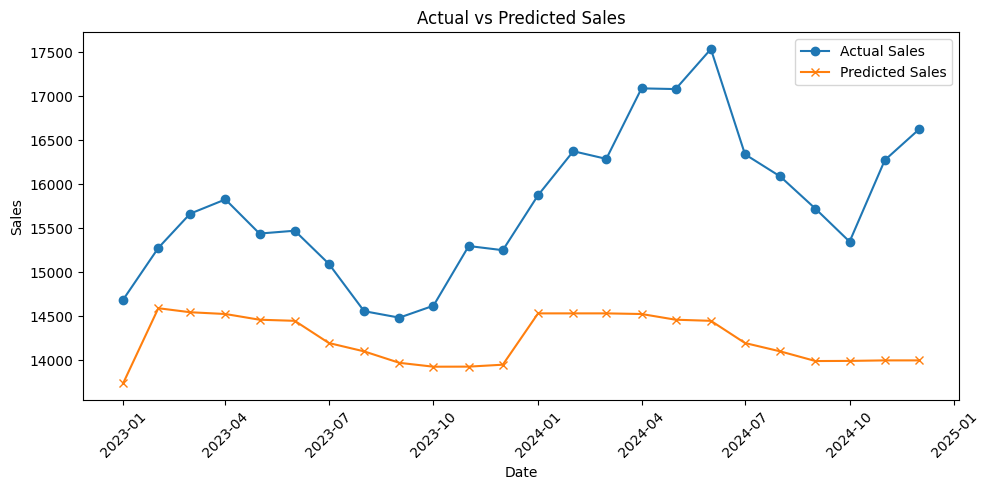


FUTURE SALES PREDICTION
Prediction Date: January 2025
Predicted Sales: 14534.15


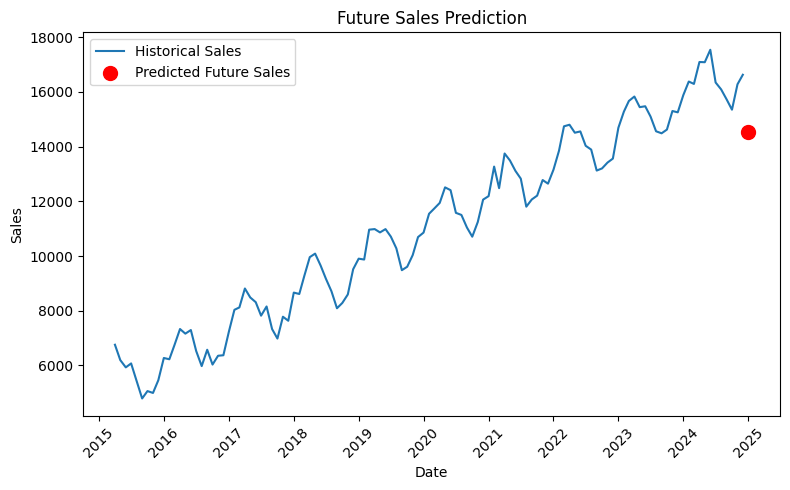

In [10]:

# FUTURE SALES PREDICTION USING RANDOM FOREST REGRESSION

# Step 1: Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Step 2: Generate sample monthly sales dataset
np.random.seed(42)

dates = pd.date_range(
    start='2015-01-01',
    periods=120,
    freq='MS'
)

trend = np.arange(120) * 100
seasonal = 1000 * np.sin(2 * np.pi * np.arange(120) / 12)
noise = np.random.normal(0, 300, 120)

sales = 5000 + trend + seasonal + noise

data = pd.DataFrame({
    'Date': dates,
    'Sales': sales
})

# Step 3: Display the dataset
print("SALES DATASET")
print(data.head(10))

print("\nDataset Information:")
print(data.info())

# Step 4: Extract date features
data['Month'] = data['Date'].dt.month
data['Year'] = data['Date'].dt.year

# Step 5: Create lag features
data['Previous_Month_Sales'] = data['Sales'].shift(1)
data['Two_Months_Ago_Sales'] = data['Sales'].shift(2)

# Step 6: Create rolling average feature
data['Rolling_Average'] = (
    data['Sales'].shift(1).rolling(window=3).mean()
)

# Step 7: Remove missing values
data.dropna(inplace=True)

# Step 8: Separate input and output variables
X = data[[
    'Month',
    'Year',
    'Previous_Month_Sales',
    'Two_Months_Ago_Sales',
    'Rolling_Average'
]]

y = data['Sales']

# Step 9: Split data chronologically
split_index = int(len(data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Step 10: Create Random Forest Regression model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Step 11: Train the model
model.fit(X_train, y_train)

print("\nModel Training Completed Successfully!")

# Step 12: Predict future sales for test data
y_pred = model.predict(X_test)

print("\nPredicted Sales:")
print(y_pred[:10])

print("\nActual Sales:")
print(y_test.iloc[:10].values)

# Step 13: Evaluate model performance
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nMODEL PERFORMANCE")
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

# Step 14: Visualize actual and predicted sales
plt.figure(figsize=(10, 5))

plt.plot(
    data['Date'].iloc[split_index:],
    y_test,
    label='Actual Sales',
    marker='o'
)

plt.plot(
    data['Date'].iloc[split_index:],
    y_pred,
    label='Predicted Sales',
    marker='x'
)

plt.xlabel("Date")
plt.ylabel("Sales")
plt.title("Actual vs Predicted Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Step 15: Predict sales for the next month
last_date = data['Date'].iloc[-1]

next_date = last_date + pd.DateOffset(months=1)

new_data = pd.DataFrame([{
    'Month': next_date.month,
    'Year': next_date.year,
    'Previous_Month_Sales': data['Sales'].iloc[-1],
    'Two_Months_Ago_Sales': data['Sales'].iloc[-2],
    'Rolling_Average': data['Sales'].iloc[-3:].mean()
}])

future_sales = model.predict(new_data)

print("\nFUTURE SALES PREDICTION")
print("Prediction Date:", next_date.strftime('%B %Y'))
print("Predicted Sales:", round(future_sales[0], 2))

# Step 16: Display future sales graph
plt.figure(figsize=(8, 5))

plt.plot(
    data['Date'],
    data['Sales'],
    label='Historical Sales'
)

plt.scatter(
    next_date,
    future_sales[0],
    color='red',
    label='Predicted Future Sales',
    s=100
)

plt.xlabel("Date")
plt.ylabel("Sales")
plt.title("Future Sales Prediction")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
